In [64]:
import pandas as pd

In [65]:
import warnings
warnings.filterwarnings("ignore") 

# First Impression

In [66]:
df = pd.read_csv("../dataset/telecom_customer_churn.csv")

pd.set_option("display.max_columns", None)

df

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,9,NaN,Yes,42.39,No,Yes,Cable,16.0,No,Yes,No,Yes,Yes,No,No,Yes,One Year,Yes,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,9,NaN,Yes,10.69,Yes,Yes,Cable,10.0,No,No,No,No,No,Yes,Yes,No,Month-to-Month,No,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,4,Offer E,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,Yes,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,13,Offer D,Yes,27.82,No,Yes,Fiber Optic,4.0,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,3,NaN,Yes,7.38,No,Yes,Fiber Optic,11.0,No,No,No,Yes,Yes,No,No,Yes,Month-to-Month,Yes,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,Female,20,No,0,La Mesa,91941,32.759327,-116.997260,0,13,Offer D,Yes,46.68,No,Yes,DSL,59.0,Yes,No,No,Yes,No,No,Yes,Yes,One Year,No,Credit Card,55.15,742.90,0.00,0,606.84,1349.74,Stayed,NaN,NaN
7039,9992-RRAMN,Male,40,Yes,0,Riverbank,95367,37.734971,-120.954271,1,22,Offer D,Yes,16.20,Yes,Yes,Fiber Optic,17.0,No,No,No,No,No,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,85.10,1873.70,0.00,0,356.40,2230.10,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,Male,22,No,0,Elk,95432,39.108252,-123.645121,0,2,Offer E,Yes,18.62,No,Yes,DSL,51.0,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,50.30,92.75,0.00,0,37.24,129.99,Joined,NaN,NaN
7041,9993-LHIEB,Male,21,Yes,0,Solana Beach,92075,33.001813,-117.263628,5,67,Offer A,Yes,2.12,No,Yes,Cable,58.0,Yes,No,Yes,Yes,No,Yes,Yes,Yes,Two Year,No,Credit Card,67.85,4627.65,0.00,0,142.04,4769.69,Stayed,NaN,NaN


In [67]:
df=df.drop(['Customer ID','Latitude','Longitude', 'Zip Code'],axis=1)

In [68]:
import pandas as pd,numpy as np
tbl=[]
for c in df.columns:
    s=df[c];n=len(s);na=s.isna().sum()
    d={'column':c,'type':s.dtype,'count':n-na,'nan_count':na,'nan_%':round(na/n*100,2),
       'count_unique':'-','top_unique':'-','min':'-','max':'-','mean':'-','median':'-','std':'-'}
    if np.issubdtype(s.dtype,np.number):
        d.update({'min':s.min(),'max':s.max(),'mean':s.mean(),'median':s.median(),'std':s.std()})
    else:
        d.update({'count_unique':s.nunique()})
        vc=s.value_counts(normalize=True).head(3)
        d['top_unique']=' '.join([f"{i} ({round(v*100,1)}%)" for i,v in vc.items()])
    tbl.append(d)
out=pd.DataFrame(tbl).sort_values('type').reset_index(drop=True)
out

,column,type,count,nan_count,nan_%,count_unique,top_unique,min,max,mean,median,std
0,Age,int64,7043,0,0.00,-,-,19,80,46.509726,46.0,16.750352
1,Number of Dependents,int64,7043,0,0.00,-,-,0,9,0.468692,0.0,0.962802
2,Number of Referrals,int64,7043,0,0.00,-,-,0,11,1.951867,0.0,3.001199
3,Tenure in Months,int64,7043,0,0.00,-,-,1,72,32.386767,29.0,24.542061
4,Total Extra Data Charges,int64,7043,0,0.00,-,-,0,150,6.860713,0.0,25.104978
5,Avg Monthly Long Distance Charges,float64,6361,682,9.68,-,-,1.01,49.99,25.420517,25.69,14.200374
6,Total Revenue,float64,7043,0,0.00,-,-,21.36,11979.34,3034.379056,2108.64,2865.204542
7,Total Long Distance Charges,float64,7043,0,0.00,-,-,0.0,3564.72,749.099262,401.44,846.660055
8,Total Refunds,float64,7043,0,0.00,-,-,0.0,49.79,1.962182,0.0,7.902614
9,Total Charges,float64,7043,0,0.00,-,-,18.8,8684.8,2280.381264,1394.55,2266.220462


# EDA

In [69]:
df_eda=df.copy()
df_eda=df_eda.drop(df_eda[df_eda["Customer Status"]=="Joined"].index)

## Churn

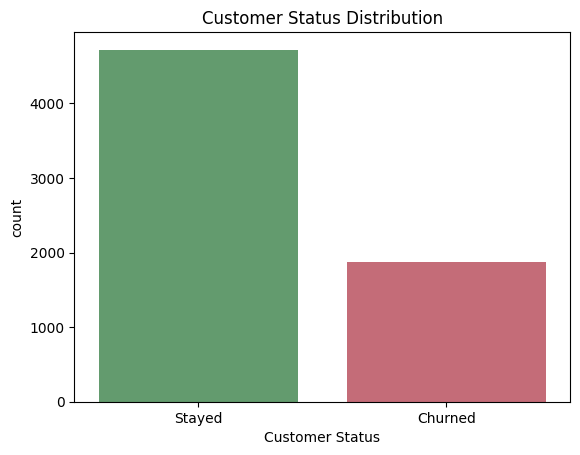

In [70]:
import seaborn as sns
import matplotlib.pyplot as plt

palette={"Stayed":"#5AA469","Churned":"#D35D6E"}

sns.countplot(x="Customer Status",data=df_eda,
              order=["Stayed","Churned"],palette=palette)
plt.title("Customer Status Distribution")
plt.show()

## Numerical vs Churn

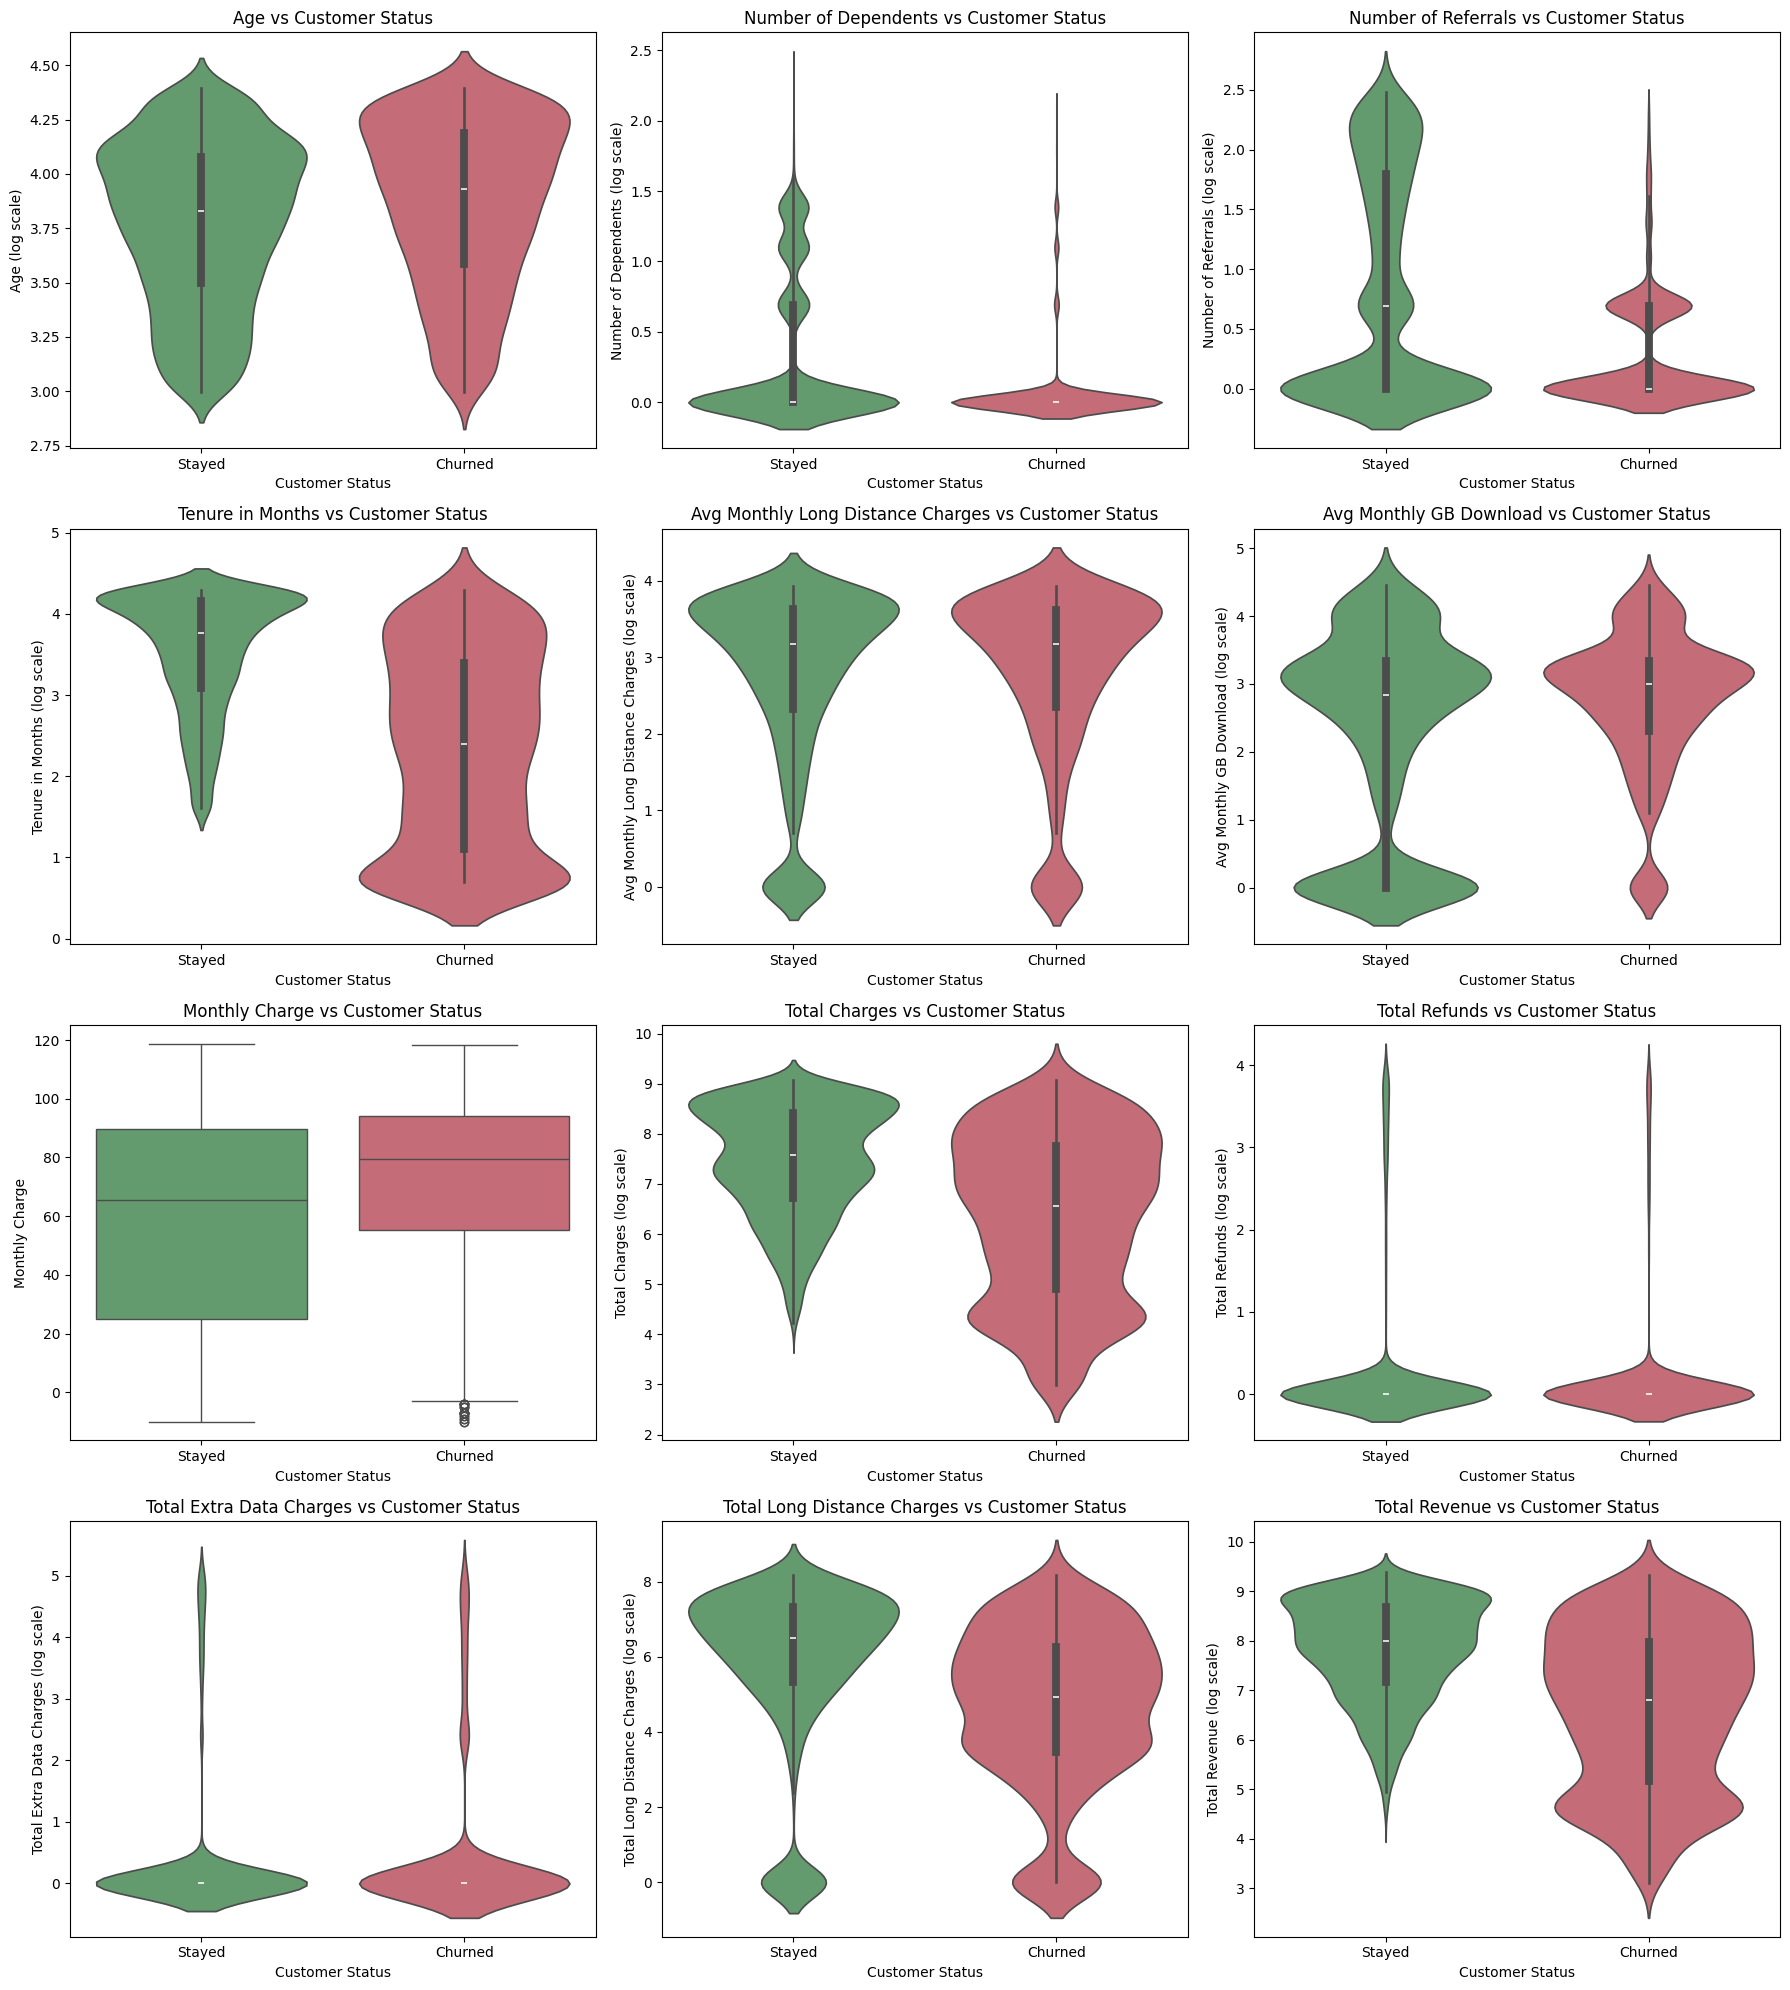

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import numpy as np

palette={"Stayed":"#5AA469","Churned":"#D35D6E"}

num_cols=df_eda.select_dtypes(include="number").columns
rows=math.ceil(len(num_cols)/3)

fig,axes=plt.subplots(rows,3,figsize=(18,5*rows))
axes=axes.flatten()

for i,c in enumerate(num_cols):
    ax=axes[i]
    data=df_eda.copy()
    col=data[c].fillna(0)
    if (col>=0).all() and col.nunique()>1:
        data[c+"_log"]=np.log1p(col)
        sns.violinplot(x="Customer Status",y=c+"_log",data=data,
                       palette=[palette["Stayed"],palette["Churned"]],
                       ax=ax,inner="box",hue_order=["Stayed","Churned"])
        ax.set_ylabel(f"{c} (log scale)")
    else:
        sns.boxplot(x="Customer Status",y=col,data=data,
                    palette=[palette["Stayed"],palette["Churned"]],
                    ax=ax,hue_order=["Stayed","Churned"])
        ax.set_ylabel(c)
    ax.set_title(f"{c} vs Customer Status")
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for j in range(i+1,len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Tenure Vs Churn

## Categorical vs Churn

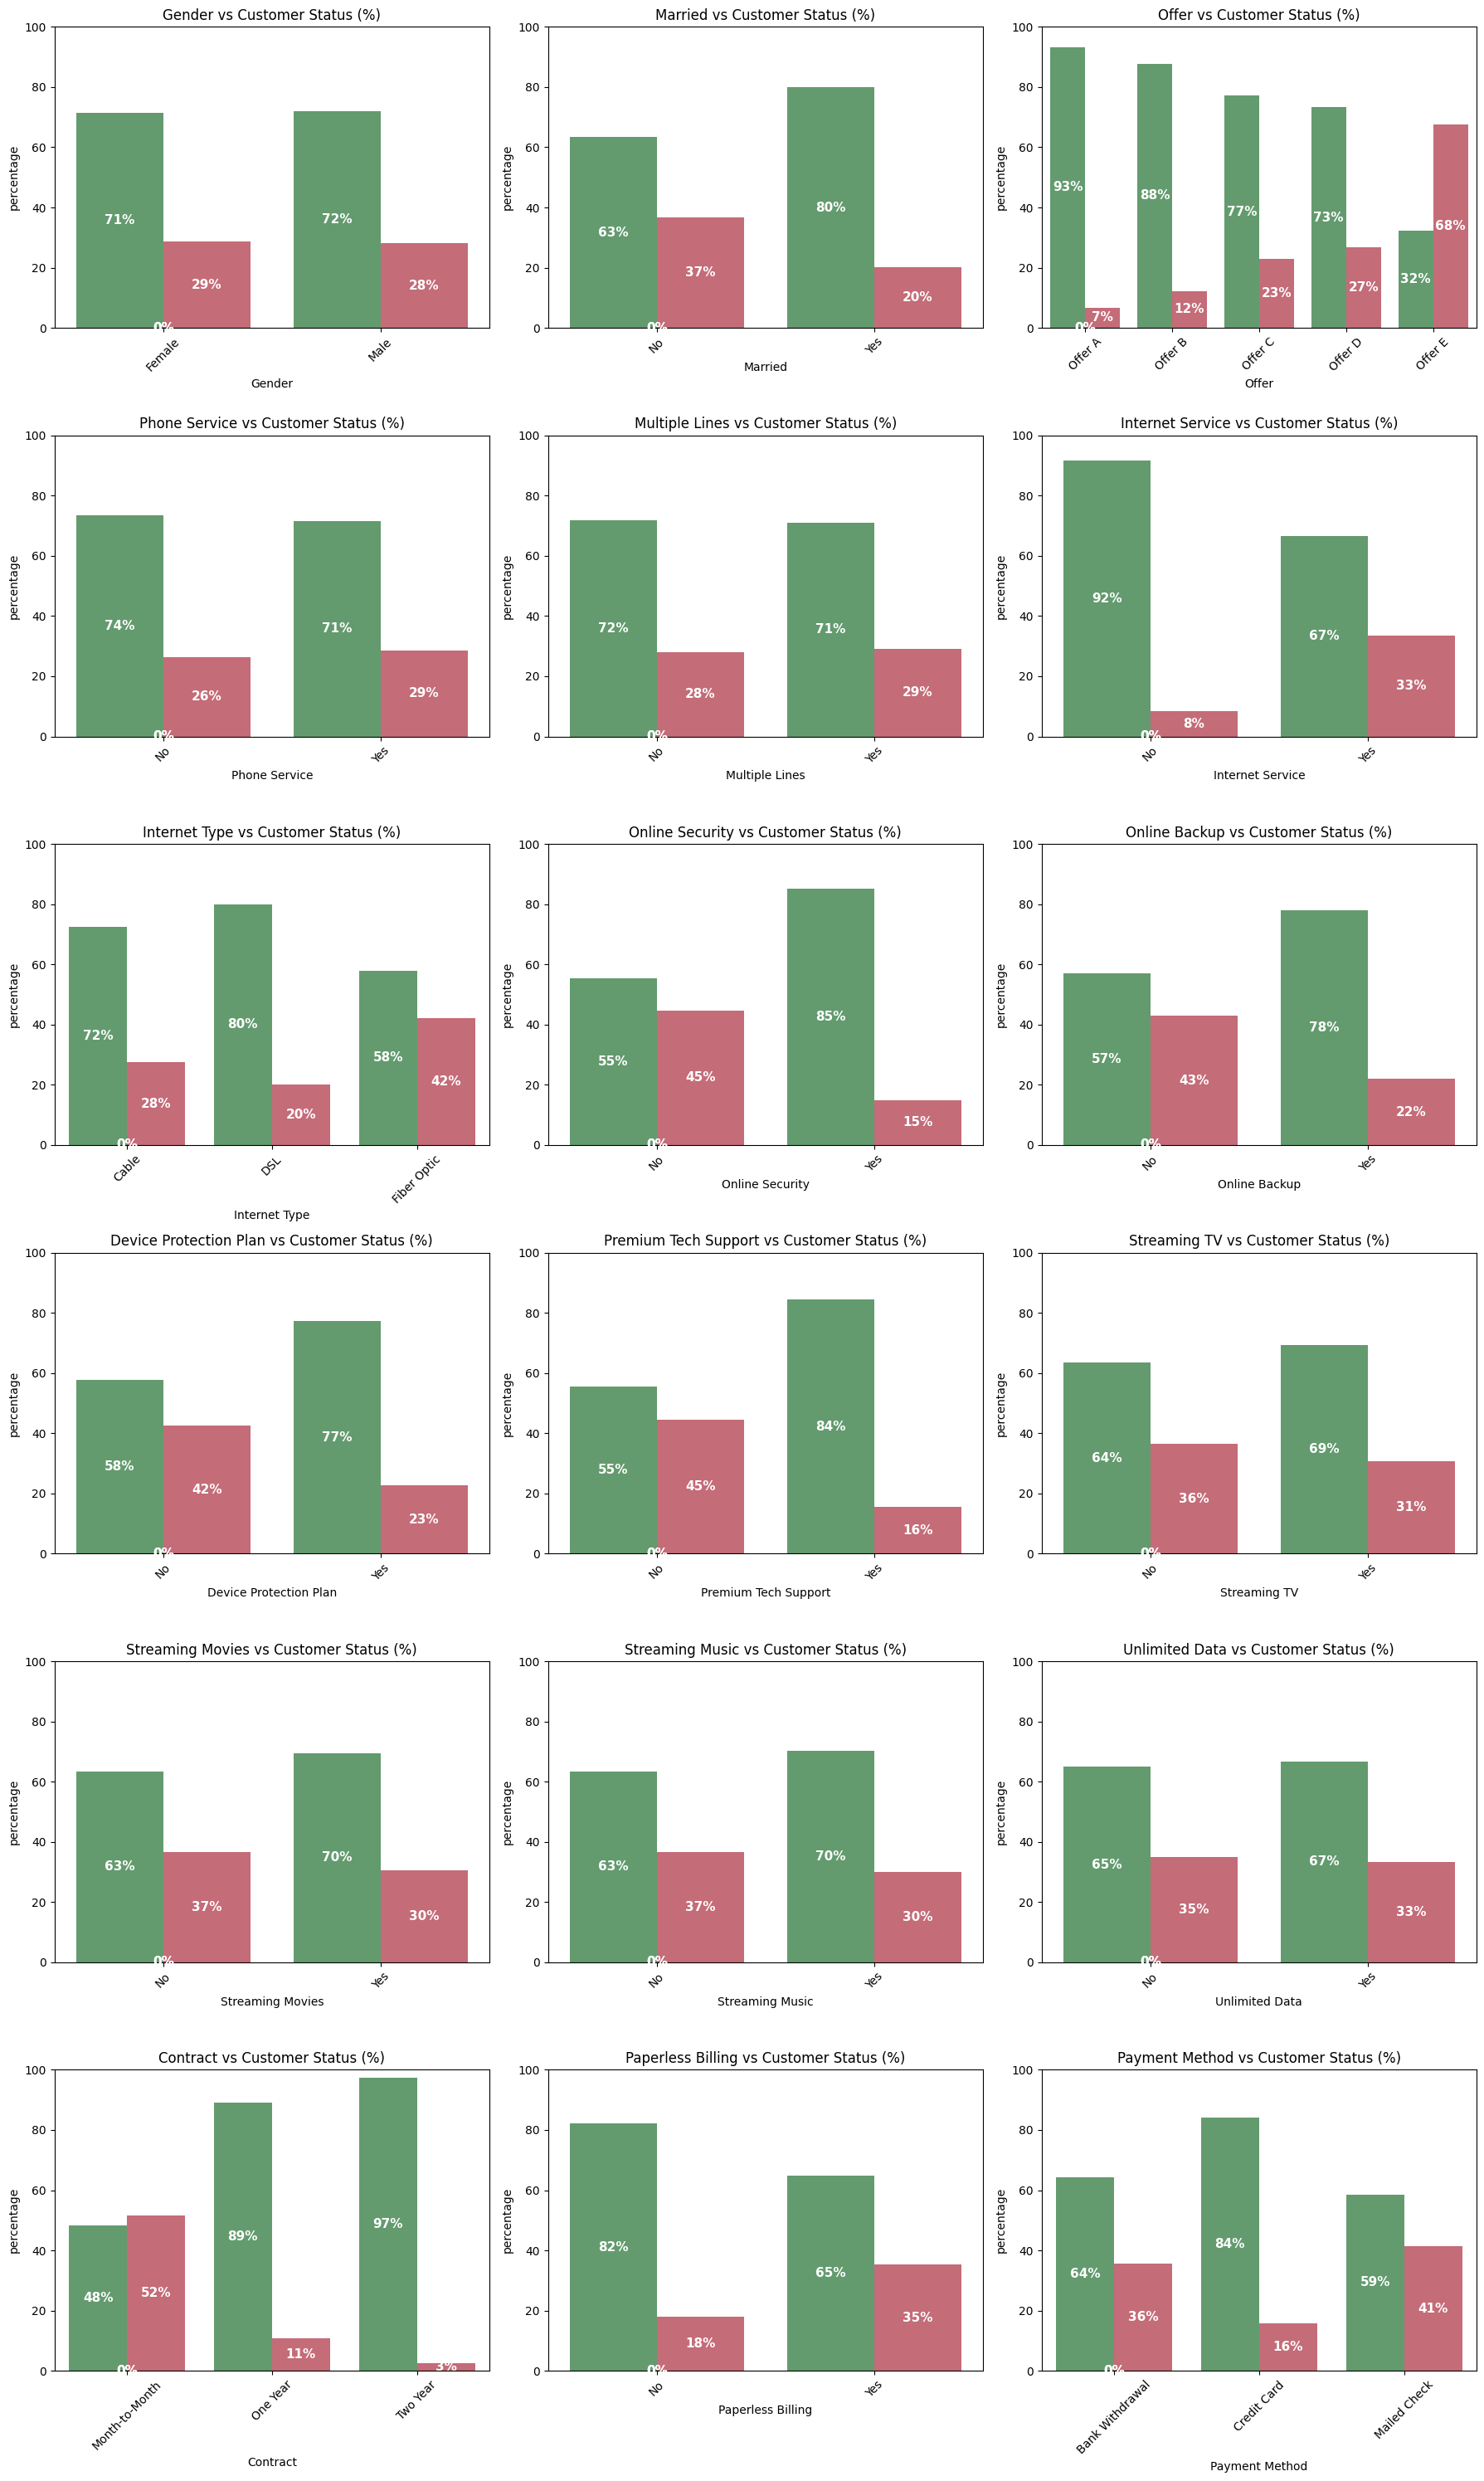

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

palette={"Stayed":"#5AA469","Churned":"#D35D6E"}

exclude=["Customer Status","Churn Category","Churn Reason","City"]
cat_cols=[c for c in df_eda.select_dtypes(include="object").columns if c not in exclude]
rows=math.ceil(len(cat_cols)/3)

fig,axes=plt.subplots(rows,3,figsize=(18,5*rows))
axes=axes.flatten()

for i,c in enumerate(cat_cols):
    ax=axes[i]
    data=df_eda.groupby([c,"Customer Status"]).size().reset_index(name="count")
    data["percentage"]=data.groupby(c)["count"].apply(lambda x: x/x.sum()*100).values
    
    sns.barplot(x=c,y="percentage",hue="Customer Status",data=data,
                palette=palette,hue_order=["Stayed","Churned"],ax=ax)

    # add percentage labels (whole numbers, bigger size)
    for p in ax.patches:
        value=f"{int(round(p.get_height()))}%"
        ax.text(p.get_x()+p.get_width()/2,
                p.get_height()/2,
                value,
                ha="center",va="center",color="white",fontsize=11,fontweight="bold")

    ax.set_title(f"{c} vs Customer Status (%)")
    ax.set_ylim(0,100)   # force 0–100 scale
    ax.tick_params(axis="x",rotation=45)
    if ax.get_legend() is not None:
        ax.get_legend().remove()

for j in range(i+1,len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

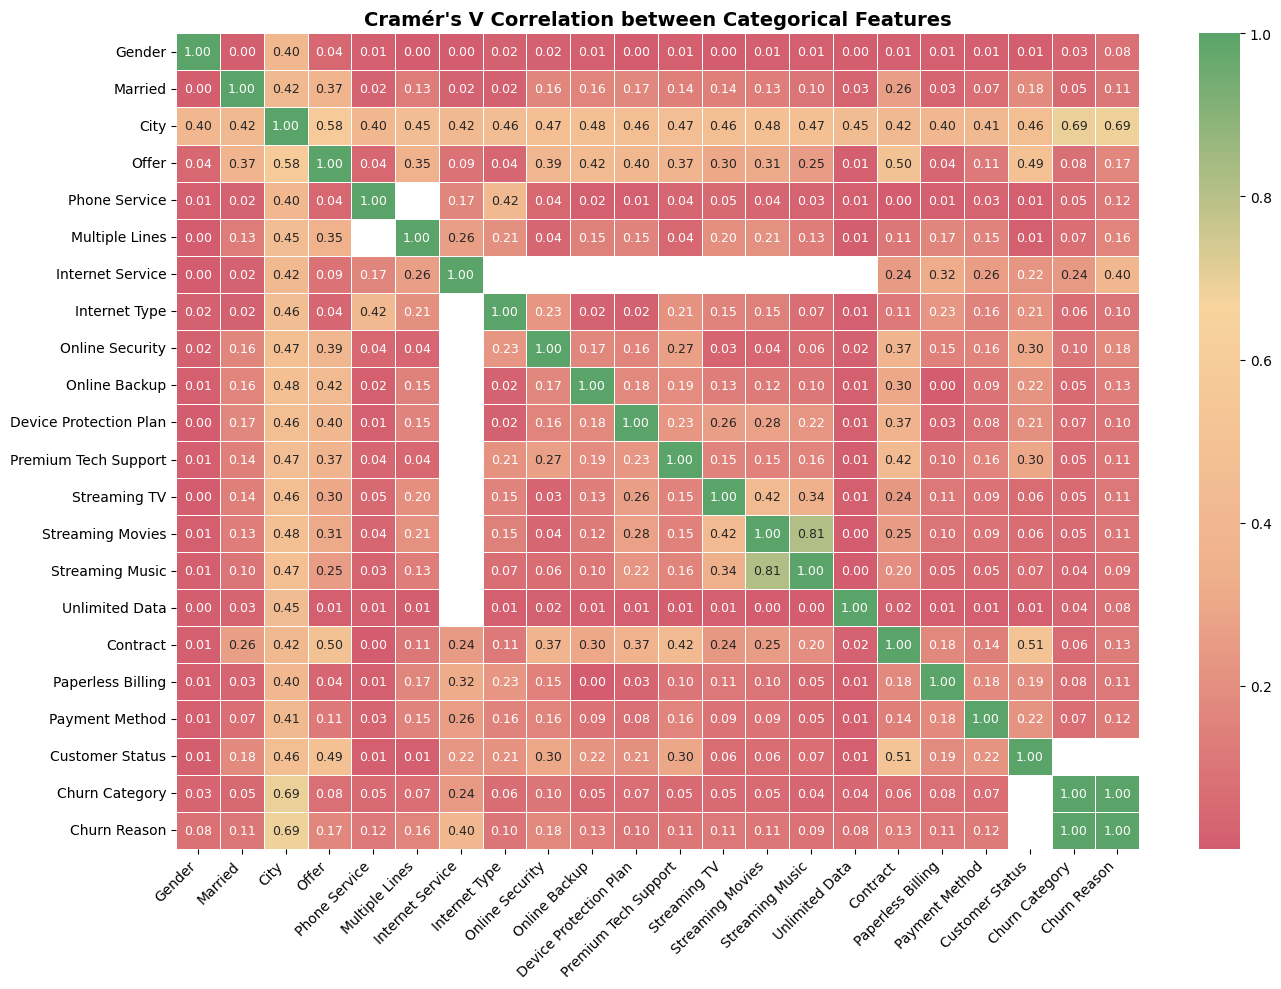

In [73]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from matplotlib.colors import LinearSegmentedColormap

# function for Cramér's V
def cramers_v(x, y):
    confusion=pd.crosstab(x,y)
    chi2=chi2_contingency(confusion)[0]
    n=confusion.sum().sum()
    r,k=confusion.shape
    return np.sqrt((chi2/n)/ (min(k-1,r-1)))

# categorical cols
cat_cols=df_eda.select_dtypes(include="object").columns

# compute matrix
corr=pd.DataFrame(index=cat_cols,columns=cat_cols,dtype=float)
for c1 in cat_cols:
    for c2 in cat_cols:
        if c1==c2:
            corr.loc[c1,c2]=1.0
        else:
            corr.loc[c1,c2]=cramers_v(df_eda[c1],df_eda[c2])

# custom palette (red → orange → yellow → green)
cmap=LinearSegmentedColormap.from_list("custom",
    ["#D35D6E","#EFB08C","#F8D49D","#5AA469"])

# plot heatmap
plt.figure(figsize=(14,10))
sns.heatmap(corr,annot=True,cmap=cmap,fmt=".2f",cbar=True,
            linewidths=0.5,linecolor="white",annot_kws={"size":9})
plt.title("Cramér's V Correlation between Categorical Features",fontsize=14,fontweight="bold")
plt.xticks(rotation=45,ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Preprocessing

## Data Cleaning

### Customer Status

In [74]:
df=df.rename(columns={"Customer Status":"Churned"})
df["Churned"]=df["Churned"].map({"Stayed":0,"Churned":1})


### Imputing Nan Value

<Axes: >

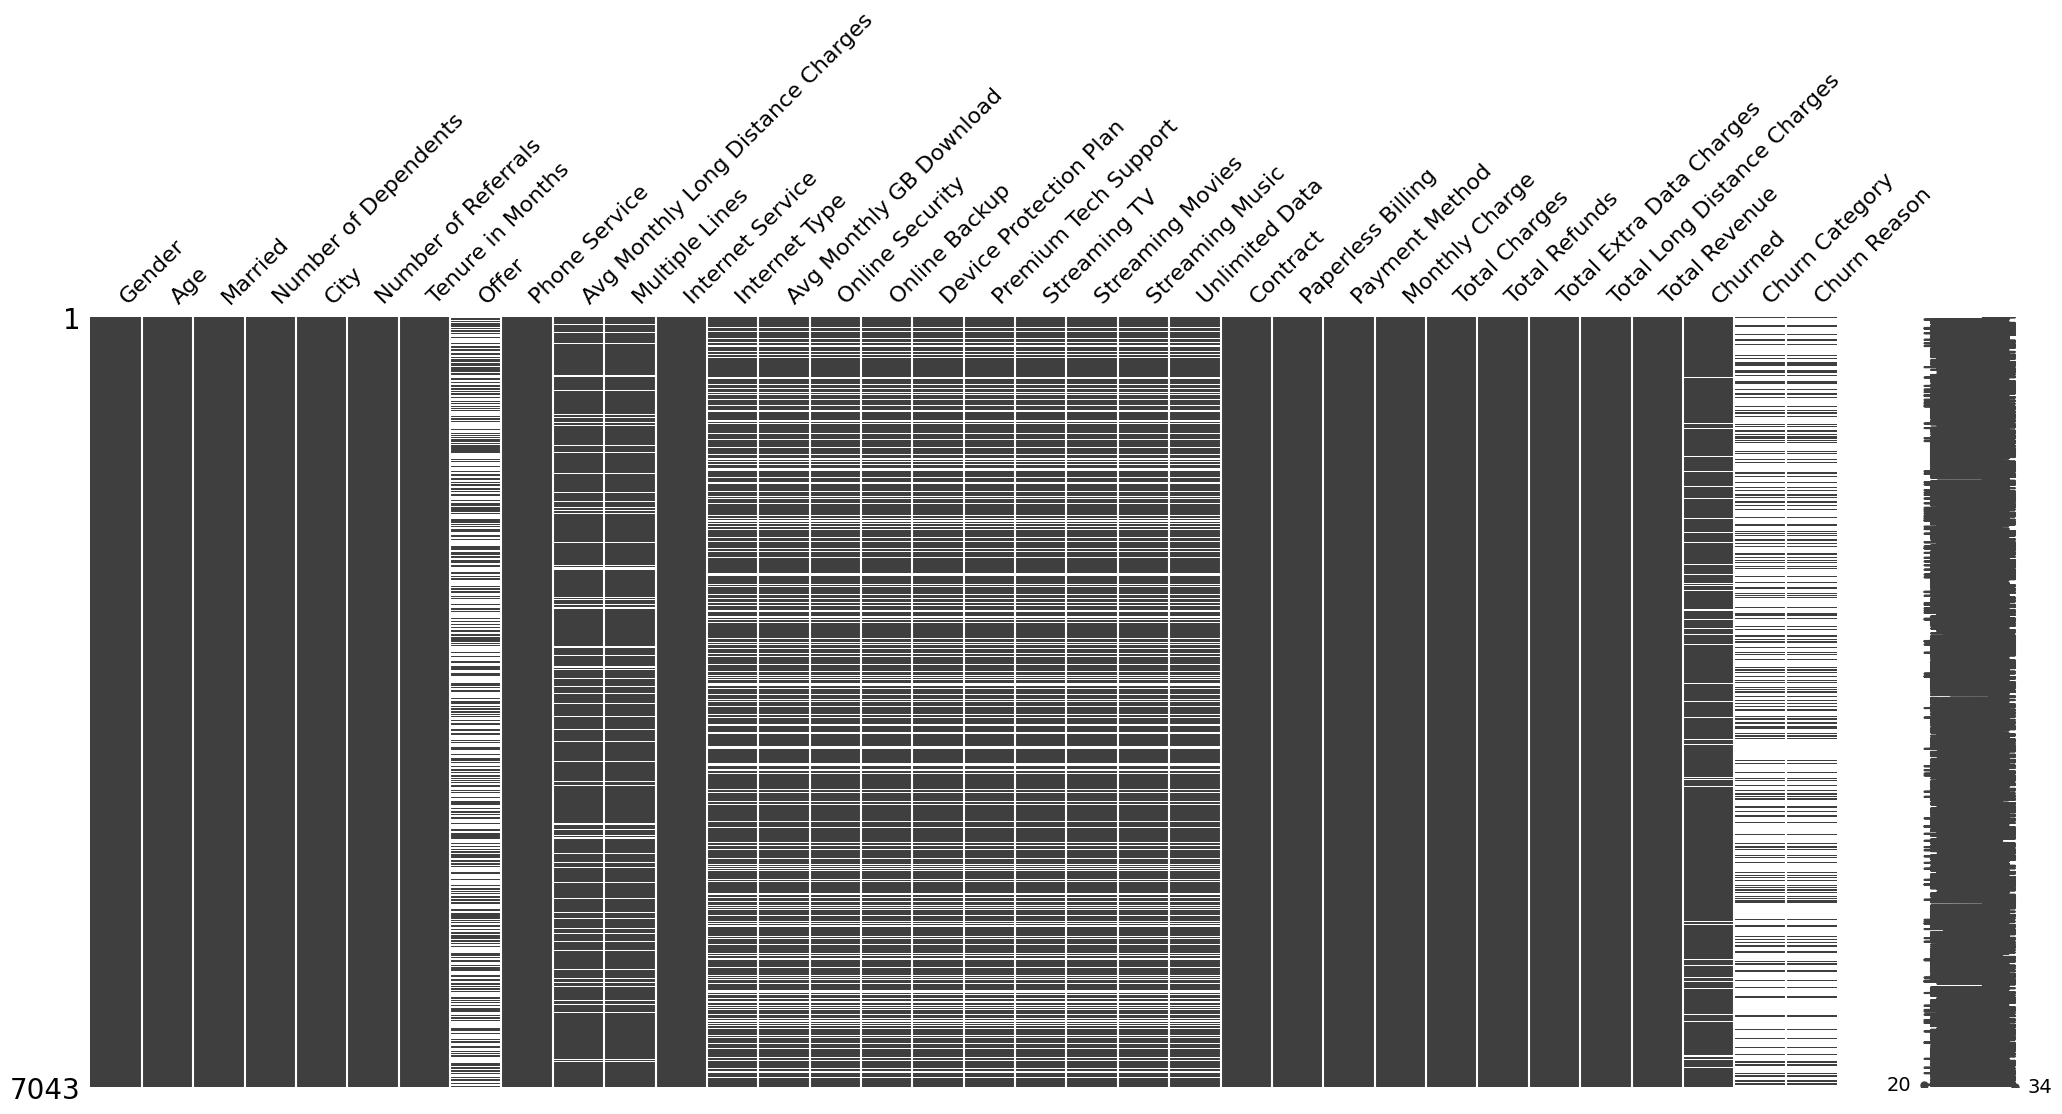

In [75]:
import missingno as msno
msno.matrix(df)

In [76]:
import pandas as pd

def inspect_nan(df):
    col_nan=(df.isna().sum()/len(df)*100).reset_index()
    col_nan.columns=["column","nan_percentage"]
    col_nan=col_nan[col_nan.nan_percentage>0].sort_values("nan_percentage",ascending=False).reset_index(drop=True)
    row_nan=df.isna().sum(axis=1).value_counts().reset_index()
    row_nan.columns=["nan_cells","row_count"]
    row_nan["percentage"]=row_nan["row_count"]/len(df)*100
    row_nan=row_nan[row_nan.nan_cells>0].sort_values("nan_cells").reset_index(drop=True)
    return col_nan,row_nan

col_report,row_report=inspect_nan(df)
print(col_report)
print(row_report)

                               column  nan_percentage
0                      Churn Category       73.463013
1                        Churn Reason       73.463013
2                               Offer       55.047565
3                       Internet Type       21.666903
4             Avg Monthly GB Download       21.666903
5                     Online Security       21.666903
6                       Online Backup       21.666903
7              Device Protection Plan       21.666903
8                Premium Tech Support       21.666903
9                        Streaming TV       21.666903
10                   Streaming Movies       21.666903
11                    Streaming Music       21.666903
12                     Unlimited Data       21.666903
13  Avg Monthly Long Distance Charges        9.683374
14                     Multiple Lines        9.683374
15                            Churned        6.446117
    nan_cells  row_count  percentage
0           1        905   12.849638
1       

## Internet Type - Unlimited Data

In [77]:
cols=["Internet Type","Avg Monthly GB Download","Online Security","Online Backup","Device Protection Plan","Premium Tech Support","Streaming TV","Streaming Movies","Streaming Music","Unlimited Data"]
nan_corr=df[cols].isna().astype(int)
nan_corr["Internet Service"]=df["Internet Service"]
report=nan_corr.groupby("Internet Service").mean()*100
report

,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data
Internet Service,,,,,,,,,,
No,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
Yes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [78]:
df["Internet Type"]=df["Internet Type"].fillna("None")
df["Avg Monthly GB Download"]=df["Avg Monthly GB Download"].fillna(0)
other_cols=["Online Security","Online Backup","Device Protection Plan","Premium Tech Support","Streaming TV","Streaming Movies","Streaming Music","Unlimited Data"]
df[other_cols]=df[other_cols].fillna("No")

In [79]:
col_report,row_report=inspect_nan(df)
print(col_report)
print(row_report)

                              column  nan_percentage
0                     Churn Category       73.463013
1                       Churn Reason       73.463013
2                              Offer       55.047565
3  Avg Monthly Long Distance Charges        9.683374
4                     Multiple Lines        9.683374
5                            Churned        6.446117
   nan_cells  row_count  percentage
0          1        957   13.587960
1          2       2043   29.007525
2          3       2531   35.936391
3          4        464    6.588102
4          5        285    4.046571
5          6         21    0.298168


## Churn Reason - Churn Category

In [80]:
churn_df=df[["Churn Category","Churn Reason"]].copy()
df=df.drop(["Churn Category","Churn Reason"],axis=1)

In [81]:
col_report,row_report=inspect_nan(df)
print(col_report)
print(row_report)

                              column  nan_percentage
0                              Offer       55.047565
1  Avg Monthly Long Distance Charges        9.683374
2                     Multiple Lines        9.683374
3                            Churned        6.446117
   nan_cells  row_count  percentage
0          1       3394   48.189692
1          2        540    7.667187
2          3        379    5.381230
3          4         21    0.298168


## Offer

In [82]:
df["Offer"]=df["Offer"].fillna("None")

In [83]:
col_report,row_report=inspect_nan(df)
print(col_report)
print(row_report)

                              column  nan_percentage
0  Avg Monthly Long Distance Charges        9.683374
1                     Multiple Lines        9.683374
2                            Churned        6.446117
   nan_cells  row_count  percentage
0          1        416    5.906574
1          2        644    9.143831
2          3         38    0.539543


## Avg Monthly Long Distance Charges - Multiple Lines

In [84]:
from sklearn.impute import KNNImputer
df["Multiple Lines"]=df["Multiple Lines"].map({"No":0,"Yes":1})
num_cols=df.select_dtypes(include="number").columns
df[num_cols]=KNNImputer(n_neighbors=5).fit_transform(df[num_cols])
df["Multiple Lines"]=df["Multiple Lines"].round().map({0:"No",1:"Yes"})

In [85]:
col_report,row_report=inspect_nan(df)
print(col_report)
print(row_report)

Empty DataFrame
Columns: [column, nan_percentage]
Index: []
Empty DataFrame
Columns: [nan_cells, row_count, percentage]
Index: []


# Feature Engineering

## Encoding

In [86]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

df_enc=df.copy()
yes_no=[c for c in df_enc.select_dtypes(include="object").columns if c not in ["City","Offer","Internet Type","Payment Method","Gender","Contract"]]
for c in yes_no:
    df_enc[c]=LabelEncoder().fit_transform(df_enc[c])
df_enc=pd.get_dummies(df_enc,columns=["Offer","Internet Type","Payment Method","Gender","Contract"],drop_first=False,dtype=int)


In [87]:
city_stats=df_enc.groupby("City")["Churned"].agg(["count","mean"]).rename(columns={"count":"n","mean":"churn_rate"}).sort_values("n",ascending=False)
print("Total unique cities:",df_enc["City"].nunique())
print(city_stats.head(20))

Total unique cities: 1106
                 n  churn_rate
City                          
Los Angeles    293    0.324232
San Diego      285    0.673684
San Jose       112    0.275000
Sacramento     108    0.296296
San Francisco  104    0.346154
Fresno          61    0.213115
Long Beach      60    0.283333
Oakland         52    0.334615
Escondido       51    0.372549
Stockton        44    0.340909
Fallbrook       43    0.651163
Glendale        40    0.475000
Bakersfield     39    0.148718
Temecula        38    0.621053
Berkeley        32    0.312500
Riverside       32    0.387500
Whittier        30    0.233333
Pasadena        30    0.300000
Anaheim         28    0.350000
Irvine          28    0.250000


In [88]:
top_cities=["Los Angeles","San Diego","San Jose","Sacramento","San Francisco"]
df_enc["City"]=df_enc["City"].where(df_enc["City"].isin(top_cities),"Other")
df_enc=pd.get_dummies(df_enc,columns=["City"],drop_first=False,dtype=int)

In [89]:
df_enc

,Age,Married,Number of Dependents,Number of Referrals,Tenure in Months,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Paperless Billing,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Churned,Offer_None,Offer_Offer A,Offer_Offer B,Offer_Offer C,Offer_Offer D,Offer_Offer E,Internet Type_Cable,Internet Type_DSL,Internet Type_Fiber Optic,Internet Type_None,Payment Method_Bank Withdrawal,Payment Method_Credit Card,Payment Method_Mailed Check,Gender_Female,Gender_Male,Contract_Month-to-Month,Contract_One Year,Contract_Two Year,City_Los Angeles,City_Other,City_Sacramento,City_San Diego,City_San Francisco,City_San Jose
0,37.0,1,0.0,2.0,9.0,1,42.390,0,1,16.0,0,1,0,1,1,0,0,1,1,65.60,593.30,0.00,0.0,381.51,974.81,0.0,1,0,0,0,0,0,1,0,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0
1,46.0,0,0.0,0.0,9.0,1,10.690,1,1,10.0,0,0,0,0,0,1,1,0,0,-4.00,542.40,38.33,10.0,96.21,610.28,0.0,1,0,0,0,0,0,1,0,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0
2,50.0,0,0.0,0.0,4.0,1,33.650,0,1,30.0,0,0,1,0,0,0,0,1,1,73.90,280.85,0.00,0.0,134.60,415.45,1.0,0,0,0,0,0,1,0,0,1,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0
3,78.0,1,0.0,1.0,13.0,1,27.820,0,1,4.0,0,1,1,0,1,1,0,1,1,98.00,1237.85,0.00,0.0,361.66,1599.51,1.0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0
4,75.0,1,0.0,3.0,3.0,1,7.380,0,1,11.0,0,0,0,1,1,0,0,1,1,83.90,267.40,0.00,0.0,22.14,289.54,1.0,1,0,0,0,0,0,0,0,1,0,0,1,0,1,0,1,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,20.0,0,0.0,0.0,13.0,1,46.680,0,1,59.0,1,0,0,1,0,0,1,1,0,55.15,742.90,0.00,0.0,606.84,1349.74,0.0,0,0,0,0,1,0,0,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,0,0
7039,40.0,1,0.0,1.0,22.0,1,16.200,1,1,17.0,0,0,0,0,0,1,1,1,1,85.10,1873.70,0.00,0.0,356.40,2230.10,1.0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,1,1,0,0,0,1,0,0,0,0
7040,22.0,0,0.0,0.0,2.0,1,18.620,0,1,51.0,0,1,0,0,0,0,0,1,1,50.30,92.75,0.00,0.0,37.24,129.99,1.0,0,0,0,0,0,1,0,1,0,0,0,1,0,0,1,1,0,0,0,1,0,0,0,0
7041,21.0,1,0.0,5.0,67.0,1,2.120,0,1,58.0,1,0,1,1,0,1,1,1,0,67.85,4627.65,0.00,0.0,142.04,4769.69,0.0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0,0,0


# Modelling

In [90]:
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.metrics import classification_report,make_scorer,f1_score

X=df_enc.drop("Churned",axis=1)
y=df_enc["Churned"].astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

scale=(y_train==0).sum()/(y_train==1).sum()

## XGBoost

In [91]:
xgb_clf=xgb.XGBClassifier(use_label_encoder=False,eval_metric="logloss",scale_pos_weight=scale,tree_method="hist")
xgb_params={"max_depth":[3,5,7],"learning_rate":[0.01,0.05,0.1],"n_estimators":[200,400,600],"subsample":[0.8,1],"colsample_bytree":[0.8,1]}
xgb_rs=RandomizedSearchCV(xgb_clf,xgb_params,n_iter=10,scoring=make_scorer(f1_score,average="macro"),cv=3,n_jobs=-1,random_state=42,verbose=0)
xgb_rs.fit(X_train,y_train)

print("XGBoost Best Params:",xgb_rs.best_params_)
print(classification_report(y_test,xgb_rs.best_estimator_.predict(X_test)))

XGBoost Best Params: {'subsample': 0.8, 'n_estimators': 600, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
              precision    recall  f1-score   support

           0       0.93      0.88      0.91       964
           1       0.77      0.87      0.81       445

    accuracy                           0.87      1409
   macro avg       0.85      0.87      0.86      1409
weighted avg       0.88      0.87      0.88      1409



# Shap Evaluation

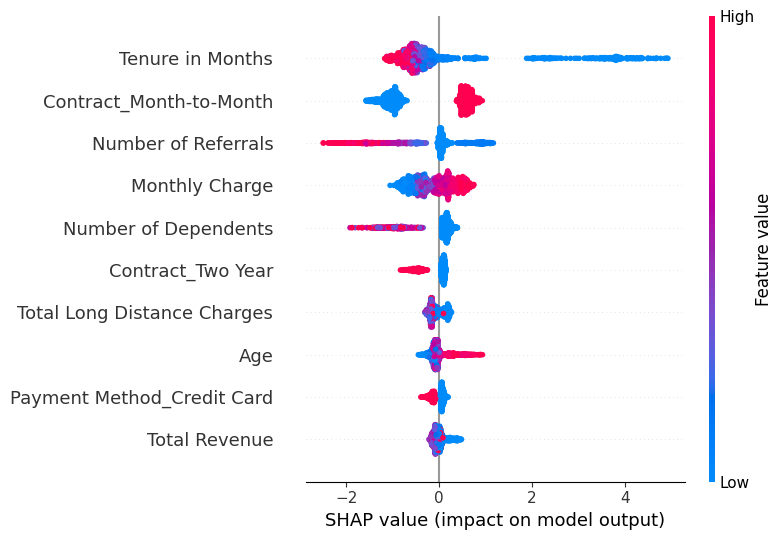

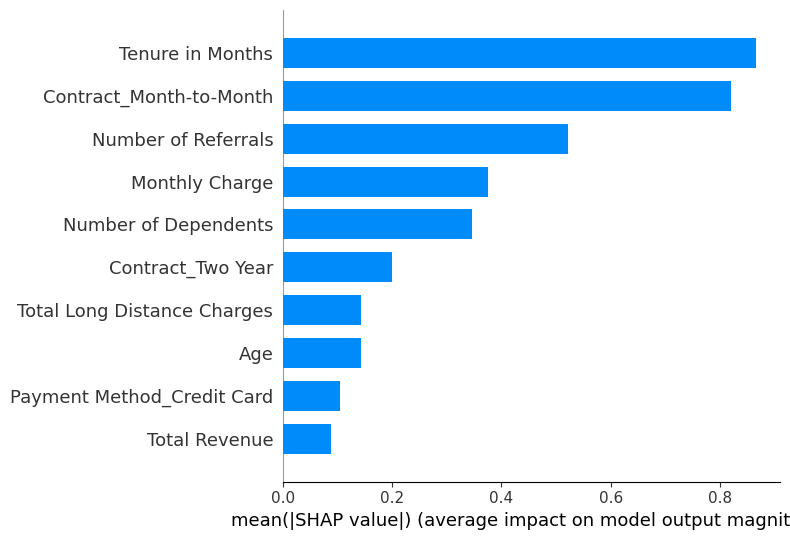

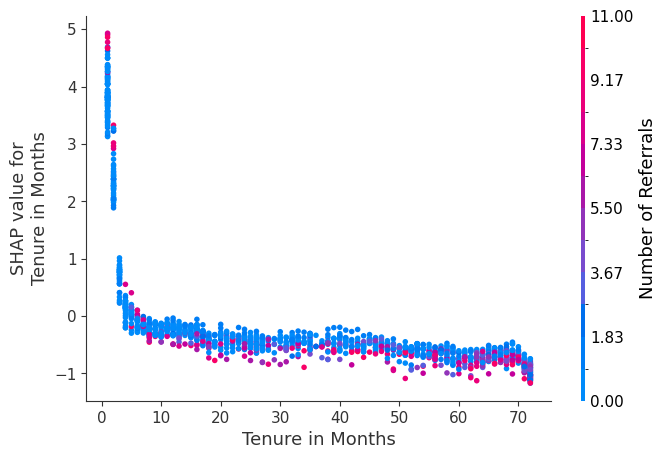

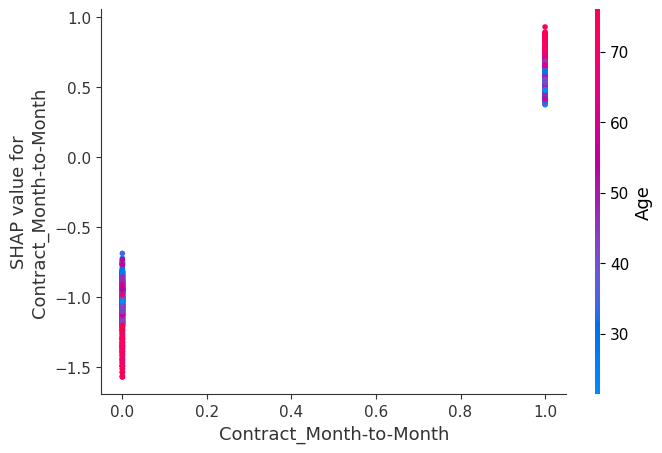

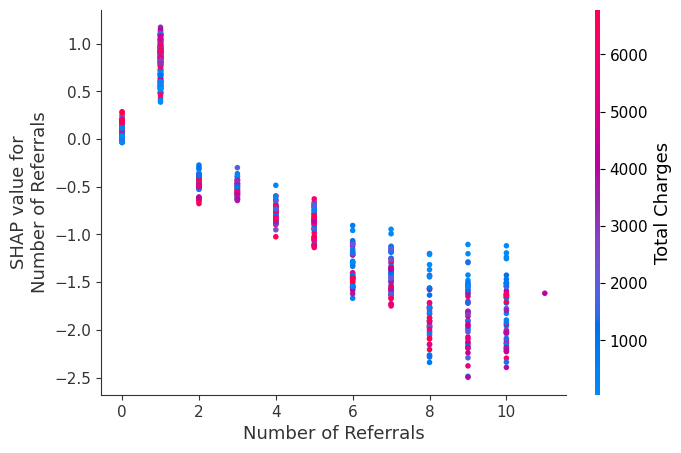

In [94]:
import shap
import matplotlib.pyplot as plt
import numpy as np

best_model=xgb_rs.best_estimator_
explainer=shap.TreeExplainer(best_model)
shap_values=explainer.shap_values(X_test)

# 1. Summary plot
shap.summary_plot(shap_values,X_test,max_display=10,show=False)
plt.savefig("shap_summary.png",transparent=True,dpi=300,bbox_inches="tight")
plt.show()
plt.close()

# 2. Bar plot
shap.summary_plot(shap_values,X_test,plot_type="bar",max_display=10,show=False)
plt.savefig("shap_bar.png",transparent=True,dpi=300,bbox_inches="tight")
plt.show()
plt.close()

# 3. Dependence plots for top 3
top_idx=np.argsort(np.abs(shap_values).mean(0))[::-1][:3]
top_names=X_test.columns[top_idx]
for f in top_names:
    shap.dependence_plot(f,shap_values,X_test,show=False)
    plt.savefig(f"shap_dependence_{f}.png",transparent=True,dpi=300,bbox_inches="tight")
    plt.show()
    plt.close()